# L03 — Exploring and Manipulating Data with Pandas
## From arrays to real tabular data

**Instructor:** Diaeddin Rimawi · **Gaza Sky Geeks · Saturday, 24 October 2026 · Lecture 3 of 30**

> **Today's challenge:** We have measurements from hundreds of penguins. How can we organize them, ask useful questions, change representations, compare groups, and save our results?

- We will use **one real dataset** throughout the lecture.
- Every Pandas operation will help answer a question about that data.
- Our route: **understand → inspect → select → filter → transform → compare → save**.

## What should you be able to do by the end?

You should be able to:

- Explain why **Pandas** is useful for tabular data and distinguish a **Series** from a **DataFrame**.
- Load a dataset and inspect its observations, attributes, labels, storage types, and missing values.
- Select rows and columns with `[]`, `.loc[]`, and `.iloc[]`.
- Filter observations using one or more conditions.
- Sort data, create columns, and make safe changes on a copy.
- Compare groups with `groupby()` and basic aggregation.
- Convert small tables to Python/NumPy structures and save or reload **CSV** and **JSON** files.

**Most importantly:** you should feel able to open an unfamiliar table and begin asking useful questions about it.

<div style="background:#17243a;color:#ffffff;padding:22px 28px;border-left:9px solid #1db8a6;border-radius:14px;">
<div style="font-size:14px;letter-spacing:2px;color:#a6e8df;">SECTION 01</div>
<div style="font-size:29px;font-weight:700;line-height:1.35;">Welcome back: from arrays to datasets</div>
<div style="font-size:16px;color:#d9e6f4;margin-top:8px;">Why NumPy is useful — and why labeled tables need something more</div>
</div>

In L02, we used **NumPy arrays** to represent structured numerical information, including a Sudoku board.

We also learned that a dataset can contain:

- **observations** — the individual rows or examples,
- **attributes** — information recorded about each observation,
- **features** — attributes used as inputs in a learning problem,
- and sometimes a **target** — an outcome we may later want to predict.

NumPy is excellent for numerical arrays. But many real datasets mix **measurements, categories, labels, dates, and missing values**.

**New question:** What if we have hundreds of observations and want meaningful column names such as `species`, `island`, and `body_mass_g`?

### Meet our dataset: Palmer Penguins

The **Palmer Penguins** dataset contains measurements of penguins observed on islands in the Palmer Archipelago, Antarctica.

For this lecture, **one row represents one recorded penguin observation**.

| Attribute | What it describes | Meaning in this lecture |
|---|---|---|
| `species` | Penguin species | categorical |
| `island` | Island where the penguin was observed | categorical |
| `bill_length_mm` | Bill length in millimeters | numerical measurement |
| `bill_depth_mm` | Bill depth in millimeters | numerical measurement |
| `flipper_length_mm` | Flipper length in millimeters | numerical measurement |
| `body_mass_g` | Body mass in grams | numerical measurement |
| `sex` | Recorded sex | categorical |
| `year` | Year of observation | time-related attribute stored as an integer |

The curated table has **344 observations and 8 attributes**. A small number of values are missing.

The `species` column could later become a **classification target**, but today we are **not training a model**. We are learning how to understand and manipulate the data.

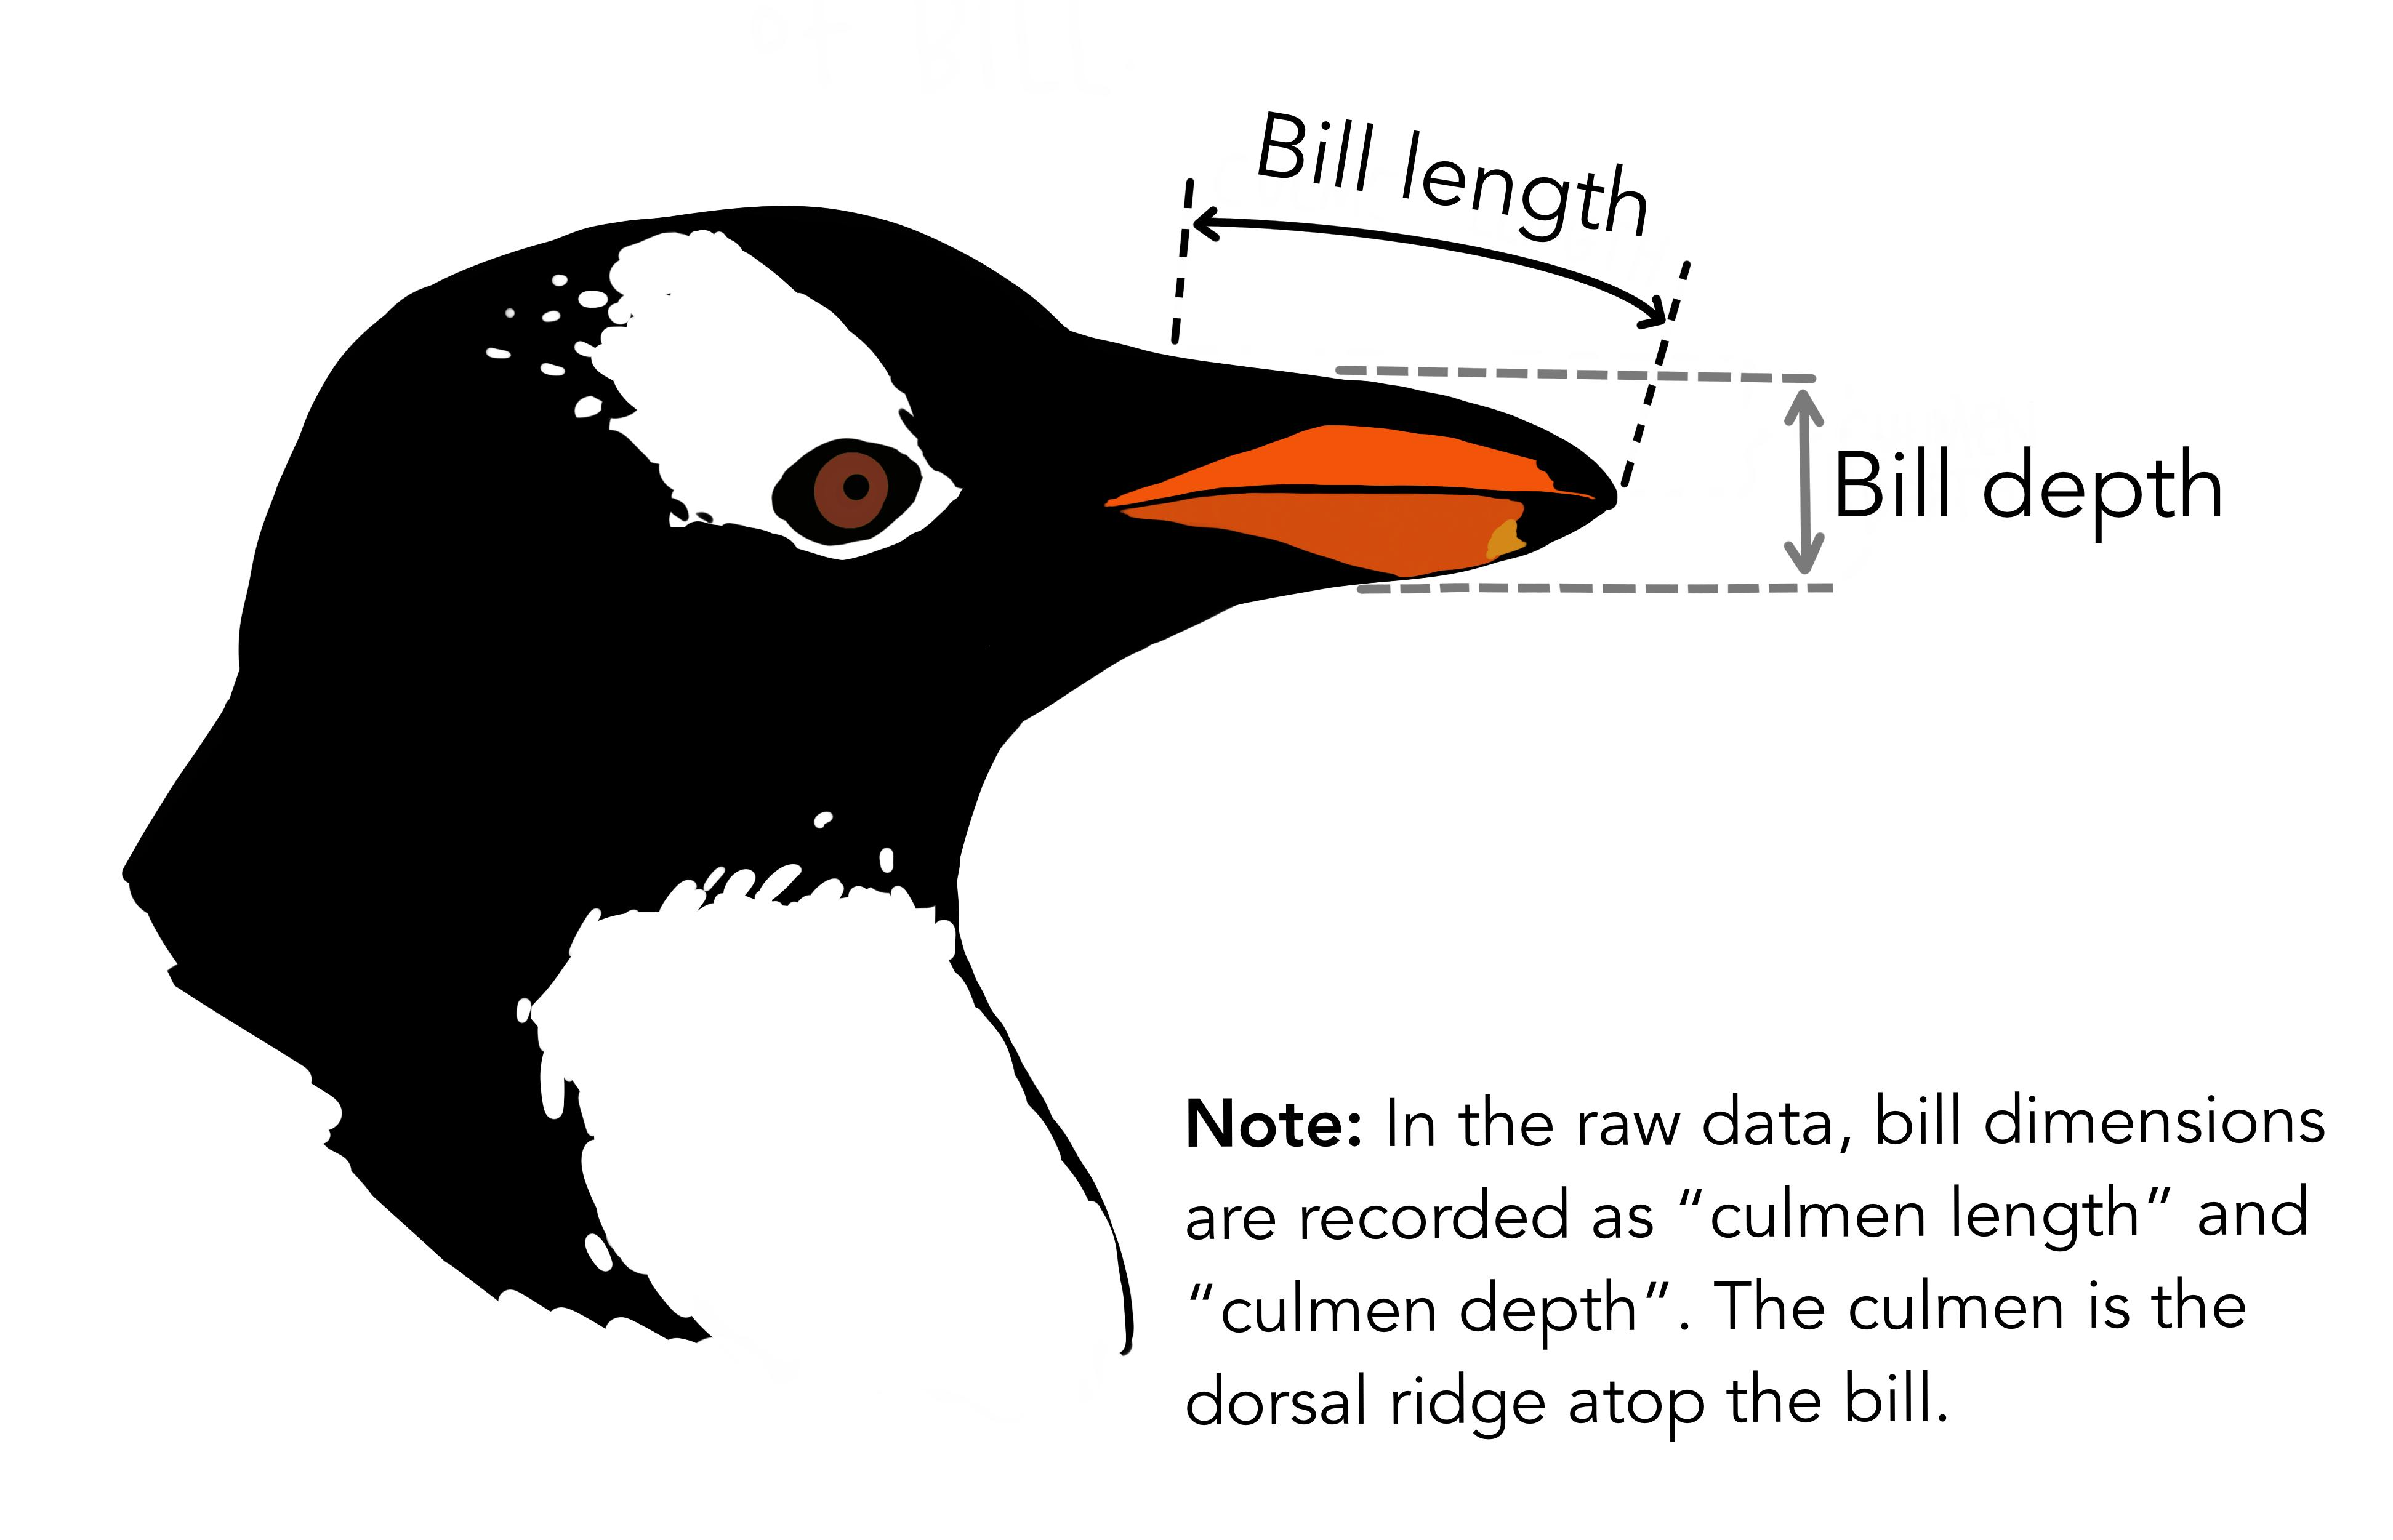

Artwork by Allison Horst

### Questions that will guide us

Instead of learning a list of commands, we will use Pandas to answer questions:

1. How many penguins and attributes do we have?
2. Which species and islands appear in the data?
3. What do the numerical measurements look like?
4. Which information is missing?
5. How do we select only the rows or columns we need?
6. Which penguins satisfy a condition such as body mass above 5,000 g?
7. How can we calculate a new column, such as kilograms?
8. How do average measurements differ across species?
9. How can we save a useful result and load it again later?

<div style="background:#17243a;color:#ffffff;padding:22px 28px;border-left:9px solid #1db8a6;border-radius:14px;">
<div style="font-size:14px;letter-spacing:2px;color:#a6e8df;">SECTION 02</div>
<div style="font-size:29px;font-weight:700;line-height:1.35;">Meet Pandas: working with tables</div>
<div style="font-size:16px;color:#d9e6f4;margin-top:8px;">A DataFrame gives rows and columns meaningful labels</div>
</div>

**Pandas** is a Python library for working with labeled tabular data.

We normally import it using the alias `pd`:

In [ ]:
from pathlib import Path

import numpy as np
import pandas as pd

pd.__version__

`read_csv()` reads a table stored in a CSV file and returns a **DataFrame**.

In [ ]:
data_path = Path("data") / "penguins.csv" # Our dataset for this lecture
penguins = pd.read_csv(data_path)
penguins.head()

A **DataFrame** is a two-dimensional labeled table:

- **rows** represent observations,
- **columns** represent attributes,
- **column labels** name the information,
- and the **index** labels the rows.

Here, Pandas created the default row index `0, 1, 2, ...`.

In [ ]:
print(type(penguins).__name__)
print("Rows and columns:", penguins.shape)
print("First row labels:", penguins.index[:5].tolist())
print("Column labels:", penguins.columns.tolist())

### One column is a Series

What if we select only the species column?

A single DataFrame column is usually returned as a **Series**: a one-dimensional labeled structure.

In [ ]:
species = penguins["species"]
print(type(species).__name__)
species.head()

### DataFrame versus NumPy array

Think back to L02:

| NumPy | Pandas |
|---|---|
| 1D or 2D numerical arrays | `Series` (1D) and `DataFrame` (2D) |
| positions are central | labels and positions are both useful |
| one array has one `dtype` | different DataFrame columns can have different dtypes |
| ideal for numerical computing | ideal for labeled tabular data |

Pandas builds closely on NumPy, but adds labels and table-oriented operations.

<div style="background:#17243a;color:#ffffff;padding:22px 28px;border-left:9px solid #1db8a6;border-radius:14px;">
<div style="font-size:14px;letter-spacing:2px;color:#a6e8df;">SECTION 03</div>
<div style="font-size:29px;font-weight:700;line-height:1.35;">First exploration: what do we know about the data?</div>
<div style="font-size:16px;color:#d9e6f4;margin-top:8px;">Before analyzing values, understand the table itself</div>
</div>

### Look at a few records

Instead of printing all 344 rows, we can inspect small parts of the table.

In [ ]:
penguins.head(8)

In [ ]:
penguins.tail(3)

`sample()` is useful when we do not want to inspect only the first or last rows.

We use a fixed `random_state` so everyone sees the same sample.

In [ ]:
penguins.sample(3, random_state=42)

### How large is the dataset?

`shape` answers two questions at once: **number of rows** and **number of columns**.

In [ ]:
n_observations, n_attributes = penguins.shape
print("Observations:", n_observations)
print("Attributes:", n_attributes)

The column labels tell us *what* was recorded, while the index tells us *how rows are labeled*.

In [ ]:
print("Columns:")
print(penguins.columns)
print()
print("Index:")
print(penguins.index)

### How does Pandas store each column?

The **real-world meaning** of an attribute and its **Pandas dtype** are different ideas.

For example, `year` represents time information, even though Pandas stores it as an integer.

In [ ]:
penguins.dtypes

`info()` combines several structural facts: number of rows, column names, non-missing counts, and dtypes.

In [ ]:
penguins.info()

### Which species are recorded?

`unique()` shows the distinct values that appear in one Series.

In [ ]:
penguins["species"].unique()

`nunique()` answers a slightly different question: **how many distinct values are there?**

In [ ]:
print("Number of species:", penguins["species"].nunique())
print("Number of islands:", penguins["island"].nunique())

### How many penguins belong to each species?

Now the values themselves matter. `value_counts()` counts how often each category appears.

In [ ]:
penguins["species"].value_counts()

The dataset contains **Adelie, Gentoo, and Chinstrap** observations. Adelie has the largest number of rows in this table.

What about the islands?

In [ ]:
penguins["island"].value_counts()

### What do the numerical measurements look like?

`describe()` gives a compact numerical summary. We will study descriptive statistics more carefully in L05.

In [ ]:
penguins.describe().round(1)

From this table we can quickly see counts, averages, ranges, and quartiles.

For example, what is the body mass range?
<details><summary><strong>Check your answer.</strong></summary>
from **2,700 g to 6,300 g** among the non-missing measurements.
</details>

This is **description**, not explanation: a difference in measurements does not tell us *why* it exists.

### Is any information missing?

`isna()` asks whether each individual value is missing. Summing the Boolean results column by column gives a useful count.

In [ ]:
penguins.isna().sum()

Some measurements and some `sex` values are missing.

For now, we only **recognize** missing information. How to clean, remove, or replace missing values belongs to **L07 — Data Quality**.

<div style="background:#17243a;color:#ffffff;padding:22px 28px;border-left:9px solid #1db8a6;border-radius:14px;">
<div style="font-size:14px;letter-spacing:2px;color:#a6e8df;">SECTION 04</div>
<div style="font-size:29px;font-weight:700;line-height:1.35;">Selecting rows and columns</div>
<div style="font-size:16px;color:#d9e6f4;margin-top:8px;">Ask for exactly the information you need</div>
</div>

We now understand the structure of the table.

**Next question:** What if we only want particular attributes or particular observations?

### Selecting columns

A single column name returns a **Series**:

In [ ]:
penguins["body_mass_g"].head()

A list of column names returns a **DataFrame**, even if the list contains only a few columns.

In [ ]:
penguins[["species", "body_mass_g"]].head()

In [ ]:
print(type(penguins["species"]).__name__)
print(type(penguins[["species"]]).__name__)

### Selection by position: `.iloc[]`

NumPy indexing from L02 was based mainly on **integer positions**.

Pandas provides `.iloc[]` for the same idea: **integer location**.

In [ ]:
# First row: position 0
penguins.iloc[0]

In [ ]:
# First 5 row positions, first 3 column positions
penguins.iloc[0:5, 0:3]

### Selection by label: `.loc[]`

`.loc[]` selects by **row and column labels**.

With the default index, row labels happen to be integers, so `.loc[0, ...]` and `.iloc[0, ...]` may look similar. They still mean different things.

In [ ]:
penguins.loc[0, "species"]

A useful difference appears with slices:

- `.loc[0:2]` uses labels and **includes** label `2`.
- `.iloc[0:2]` follows normal Python positional slicing and **stops before** position `2`.

In [ ]:
print("loc: labels 0 through 2")
display(penguins.loc[0:2, ["species", "island"]])

print("iloc: positions 0 up to, but not including, 2")
display(penguins.iloc[0:2, 0:2])

**Rule of thumb:**

- Use `.loc[]` when your selection is described by **labels or conditions**.
- Use `.iloc[]` when your selection is described by **integer positions**.

### Activity A — Select information

Write code that:

1. selects only `species`, `island`, and `flipper_length_mm`, and
2. retrieves the first three rows and first two columns using `.iloc[]`.

In [ ]:
# Your turn

pass

<details>
<summary><strong>Suggested answer</strong></summary>

```python
penguins[["species", "island", "flipper_length_mm"]]
penguins.iloc[0:3, 0:2]
```

The first expression selects by **column labels**. The second selects by **positions**.

</details>

<div style="background:#17243a;color:#ffffff;padding:22px 28px;border-left:9px solid #1db8a6;border-radius:14px;">
<div style="font-size:14px;letter-spacing:2px;color:#a6e8df;">SECTION 05</div>
<div style="font-size:29px;font-weight:700;line-height:1.35;">Finding observations: filtering</div>
<div style="font-size:16px;color:#d9e6f4;margin-top:8px;">Turn questions into Boolean conditions</div>
</div>

Selection by position or label is useful when we already know *where* the data is.

But often our question describes a **condition** instead.

> Which penguins belong to the Gentoo species?

### Start with a Boolean mask

The comparison below is performed for every row. The result is a Series of `True` and `False` values.

In [ ]:
gentoo_mask = penguins["species"] == "Gentoo"
gentoo_mask.head(10)

We can use that mask to keep only rows where the condition is `True`.

In [ ]:
gentoo_penguins = penguins[gentoo_mask]
gentoo_penguins.head()

There are 124 Gentoo observations:

In [ ]:
len(gentoo_penguins)

### Numerical conditions

What if we want penguins with recorded body mass above **5,000 g**?

In [ ]:
heavy_penguins = penguins[penguins["body_mass_g"] > 5000]
heavy_penguins[["species", "island", "body_mass_g"]].head(10)

A Boolean Series can also be summed because `True` behaves like 1 and `False` like 0.

In [ ]:
(penguins["body_mass_g"] > 5000).sum()

### Combining conditions

Now ask a more specific question:

> Which **Gentoo** penguins have body mass above **5,000 g**?

Each condition creates a Boolean Series. `&` combines them element by element.

In [ ]:
heavy_gentoo = penguins[
    (penguins["species"] == "Gentoo")
    & (penguins["body_mass_g"] > 5000)
]

heavy_gentoo[["species", "island", "body_mass_g"]].head()

For Pandas conditions:

- `&` means element-wise **AND**,
- `|` means element-wise **OR**,
- `~` means element-wise **NOT**,
- and each comparison should be placed inside **parentheses**.

Python's ordinary `and` and `or` do not combine entire Pandas Series element by element.

In [ ]:
dream_or_torgersen = penguins[
    (penguins["island"] == "Dream")
    | (penguins["island"] == "Torgersen")
]

not_adelie = penguins[~(penguins["species"] == "Adelie")]

print("Dream or Torgersen observations:", len(dream_or_torgersen))
print("Non-Adelie observations:", len(not_adelie))

When several allowed values are acceptable, `isin()` is often easier to read.

In [ ]:
penguins[penguins["species"].isin(["Adelie", "Chinstrap"])][
    ["species", "island", "body_mass_g"]
].head()

### Which observations are missing body mass?

Now that we know filtering, we can return to a question from our first exploration.

In [ ]:
penguins[penguins["body_mass_g"].isna()]

Only two observations have missing body mass.

### Activity B — Build a two-condition filter

Find **Chinstrap** penguins with body mass greater than **3,800 g**.

Before running the code, say in words what each condition means.

In [ ]:
# Your turn

pass

<details>
<summary><strong>Suggested answer</strong></summary>

```python
penguins[
    (penguins["species"] == "Chinstrap")
    & (penguins["body_mass_g"] > 3800)
]
```

The result contains only rows where **both** conditions are `True`.

</details>

<div style="background:#17243a;color:#ffffff;padding:22px 28px;border-left:9px solid #1db8a6;border-radius:14px;">
<div style="font-size:14px;letter-spacing:2px;color:#a6e8df;">SECTION 06</div>
<div style="font-size:29px;font-weight:700;line-height:1.35;">Manipulating and transforming data</div>
<div style="font-size:16px;color:#d9e6f4;margin-top:8px;">Reorder rows, calculate new information, and modify safely</div>
</div>

So far, we have inspected and selected existing values.

**Next question:** What if we want to reorganize the data or calculate information that is not explicitly stored?

### Sorting

Which penguins have the greatest recorded body mass?

In [ ]:
penguins.sort_values("body_mass_g", ascending=False)[
    ["species", "island", "body_mass_g"]
].head()

`ascending=False` places larger values first.

We can also sort using more than one column.

In [ ]:
penguins.sort_values(
    ["species", "body_mass_g"],
    ascending=[True, False]
)[["species", "body_mass_g"]].head(8)

### Creating a new column

Body mass is stored in grams. What if we want kilograms too?

We first make a copy so our original scientific table remains unchanged.

In [ ]:
penguins_enriched = penguins.copy()
penguins_enriched["body_mass_kg"] = penguins_enriched["body_mass_g"] / 1000

penguins_enriched[["species", "body_mass_g", "body_mass_kg"]].head()

This is similar to NumPy element-wise arithmetic: the division is applied to the entire Series.

The original DataFrame still has only its original columns:

In [ ]:
print("body_mass_kg" in penguins.columns)
print("body_mass_kg" in penguins_enriched.columns)

### Modifying selected values safely

Sometimes we need to change selected cells. We should be explicit about the object we are changing.

The example below is **hypothetical practice only**. It changes a separate copy, not the scientific data.

In [ ]:
practice_copy = penguins.loc[0:2, ["species", "body_mass_g"]].copy()
practice_copy.loc[0, "body_mass_g"] = 9999  # hypothetical value for demonstration

print("Modified practice copy:")
display(practice_copy)

print("Original row 0 is unchanged:")
display(penguins.loc[[0], ["species", "body_mass_g"]])

### Renaming and dropping columns

Many Pandas operations return a **new object** by default. This makes transformations easier to follow.

In [ ]:
renamed = penguins[["species", "body_mass_g"]].head().rename(
    columns={"body_mass_g": "mass_g"}
)
renamed

In [ ]:
without_mass = renamed.drop(columns="mass_g")
without_mass

We will use more substantial transformations and feature engineering in later lectures. For now, focus on **clear, controlled changes**.

### Activity C — Create one useful measurement

Make a copy of the dataset and create a column called `flipper_length_cm` by converting millimeters to centimeters.

Then display `species`, `flipper_length_mm`, and `flipper_length_cm` for the first five rows.

In [ ]:
# Your turn

pass

<details>
<summary><strong>Suggested answer</strong></summary>

```python
practice = penguins.copy()
practice["flipper_length_cm"] = practice["flipper_length_mm"] / 10
practice[["species", "flipper_length_mm", "flipper_length_cm"]].head()
```

The new column is calculated element by element from an existing measurement.

</details>

<div style="background:#17243a;color:#ffffff;padding:22px 28px;border-left:9px solid #1db8a6;border-radius:14px;">
<div style="font-size:14px;letter-spacing:2px;color:#a6e8df;">SECTION 07</div>
<div style="font-size:29px;font-weight:700;line-height:1.35;">Comparing groups: aggregation and groupby()</div>
<div style="font-size:16px;color:#d9e6f4;margin-top:8px;">Move from individual rows to summaries of whole groups</div>
</div>

We can now find individual penguins that match a condition.

But what if our question is about **groups**?

> Do the three species have different average body masses in these records?

### The idea: split → apply → combine

```text
All penguin rows
      ↓ split by species
Adelie | Chinstrap | Gentoo
      ↓ apply the same calculation to each group
        mean body mass
      ↓ combine
one result table with one value per species
```

Pandas provides this pattern through `groupby()`.

### Group size

We already used `value_counts()` to count species. `groupby().size()` expresses the same idea through grouping:

In [ ]:
penguins.groupby("species").size()

`size()` counts **rows in each group**.

`count()` counts **non-missing values** in a selected column. Because two body-mass values are missing, the results differ slightly.

In [ ]:
group_sizes = penguins.groupby("species").size()
body_mass_counts = penguins.groupby("species")["body_mass_g"].count()

pd.DataFrame({
    "group_size": group_sizes,
    "non_missing_body_mass": body_mass_counts,
})

### Average body mass by species

In [ ]:
penguins.groupby("species")["body_mass_g"].mean().round(1)

Gentoo has the largest average body mass in these observations.

This is a **descriptive comparison**. It does not establish a cause.

### Average flipper length by species

In [ ]:
penguins.groupby("species")["flipper_length_mm"].mean().round(1)

By default, Pandas aggregation functions such as `mean()` ignore missing numerical values rather than treating them as zero.

### Several summaries together with `agg()`

Sometimes one average is not enough. We may want several simple summaries in one result.

In [ ]:
species_summary = penguins.groupby("species").agg(
    average_body_mass_g=("body_mass_g", "mean"),
    minimum_body_mass_g=("body_mass_g", "min"),
    maximum_body_mass_g=("body_mass_g", "max"),
    average_flipper_mm=("flipper_length_mm", "mean"),
).round(1)

species_summary

The syntax is more compact than repeatedly filtering each species ourselves.

The important idea is not the exact spelling of `agg()`. It is the pattern: **define groups, apply a calculation, combine the results**.

<details>
<summary><strong>Optional: group by two attributes</strong></summary>

We can also create groups using more than one attribute:

```python
penguins.groupby(["species", "island"])["body_mass_g"].mean().round(1)
```

This creates species–island combinations. We will not study hierarchical indexes in this lecture.

</details>

### Activity D

Calculate the **mean bill length** for each species.

In [ ]:
# Your turn
penguins.groupby("species")["bill_length_mm"].mean().round(1)


<details>
<summary><strong>Suggested answer</strong></summary>

```python
penguins.groupby("species")["bill_length_mm"].mean().round(1)
```

You should get one average bill length for each of the three species.

</details>

<div style="background:#17243a;color:#ffffff;padding:22px 28px;border-left:9px solid #1db8a6;border-radius:14px;">
<div style="font-size:14px;letter-spacing:2px;color:#a6e8df;">SECTION 08</div>
<div style="font-size:29px;font-weight:700;line-height:1.35;">From Pandas to files: saving and loading data</div>
<div style="font-size:16px;color:#d9e6f4;margin-top:8px;">A DataFrame lives in memory; a file lets us keep or exchange it</div>
</div>

Until now, our DataFrame has existed in Python memory.

**What happens when we close Python?**

It helps to separate three ideas:

1. **Data structure in memory** — for example a list, NumPy array, Series, or DataFrame.
2. **Stored representation** — for example CSV or JSON on disk.
3. **Loading** — reading stored information back into a program.

The same information can be represented in several ways.

### From a DataFrame to Python records

A list of dictionaries is a common Python representation of records.

In [ ]:
small_table = penguins[["species", "island", "body_mass_g"]].head(3)
records = small_table.to_dict(orient="records")
records

Each dictionary represents one row.

We can also convert selected numerical columns to a NumPy array.

In [ ]:
numeric_array = penguins[["bill_length_mm", "body_mass_g"]].head(5).to_numpy()
print(type(numeric_array).__name__)
print("Shape:", numeric_array.shape)
numeric_array

Be careful: converting the **entire mixed DataFrame** to NumPy does not automatically produce a clean numerical feature matrix for Machine Learning.

We still need to choose meaningful features and later deal with categories and missing values.

### CSV: a simple tabular text format

A CSV file usually stores:

- one record per row,
- fields separated by a delimiter such as a comma,
- and often column names in the first row.

This is the format we loaded at the beginning.

In [ ]:
output_dir = Path("outputs")
output_dir.mkdir(exist_ok=True)

analysis_subset = penguins.loc[
    penguins["body_mass_g"] > 5000,
    ["species", "island", "body_mass_g"],
].copy()
analysis_subset["body_mass_kg"] = analysis_subset["body_mass_g"] / 1000
analysis_subset.head()

`to_csv()` stores the DataFrame. We use `index=False` because our current row index is only an internal label, not a scientific attribute.

In [ ]:
csv_path = output_dir / "heavy_penguins.csv"
analysis_subset.to_csv(csv_path, index=False)

csv_loaded = pd.read_csv(csv_path)
csv_loaded.head()

Let's verify the round trip: save → load → compare.

In [ ]:
pd.testing.assert_frame_equal(
    analysis_subset.reset_index(drop=True),
    csv_loaded,
    check_dtype=False,
)
print("CSV round trip verified.")

CSV is widely supported, but it is fundamentally a **text representation**. It does not preserve every Python or Pandas type detail automatically.

### JSON: records and nested structures

JSON can represent objects, lists, values, and nested structures.

Using `orient="records"`, each DataFrame row becomes a JSON object inside a list.

In [ ]:
json_preview = analysis_subset.head(2).to_json(
    orient="records",
    indent=2,
)
print(json_preview)

In [ ]:
json_path = output_dir / "heavy_penguins.json"
analysis_subset.to_json(json_path, orient="records", indent=2)

json_loaded = pd.read_json(json_path, orient="records")
json_loaded.head()

In [ ]:
pd.testing.assert_frame_equal(
    analysis_subset.reset_index(drop=True),
    json_loaded,
    check_dtype=False,
)
print("JSON round trip verified.")

### CSV and JSON are not the only choices

| Format | Useful idea | Common Pandas methods | Live today? |
|---|---|---|---|
| **CSV** | simple tabular text; easy to exchange | `read_csv()`, `to_csv()` | yes |
| **JSON** | records or nested structures | `read_json()`, `to_json()` | yes |
| **Excel (`.xlsx`)** | familiar workbook format; multiple sheets | `read_excel()`, `to_excel()` | concept only |
| **Parquet** | column-oriented analytical storage; efficient for large tables | `read_parquet()`, `to_parquet()` | concept only |
| **SQL database** | persistent related tables queried from a database | `read_sql()`, `to_sql()` | concept only |

Excel and Parquet often require optional libraries. We keep the executable lecture path dependency-light and focus on CSV and JSON.

<details>
<summary><strong>Optional independent practice: transfer your skills to Iris</strong></summary>

Use the classic **Iris** dataset from the UCI Machine Learning Repository:

https://archive.ics.uci.edu/dataset/53/iris

Try to:

1. load the dataset,
2. display its first five observations,
3. identify its numerical attributes,
4. filter one flower species,
5. calculate one grouped numerical summary.

The goal is not to learn new Pandas functions. It is to see whether the same ideas transfer to unfamiliar data.

</details>

<div style="background:#17243a;color:#ffffff;padding:22px 28px;border-left:9px solid #1db8a6;border-radius:14px;">
<div style="font-size:14px;letter-spacing:2px;color:#a6e8df;">SECTION 09</div>
<div style="font-size:29px;font-weight:700;line-height:1.35;">What did we learn?</div>
<div style="font-size:16px;color:#d9e6f4;margin-top:8px;">One real dataset, one connected path through Pandas</div>
</div>

### Up next: L04 — Visualizing Data and Discovering Patterns

Today we learned how to **ask for the right rows, columns, and summaries**.

Next, we will ask a new question:

> **Can we see patterns that are difficult to notice in tables alone?**

We will use visualizations to explore distributions, comparisons, and relationships in the same spirit: **question → representation → interpretation**.

<details>
<summary><strong>Sources, acknowledgements, and further reading</strong></summary>

## Dataset

- **Palmer Penguins:** Allison Horst, Alison Hill, and Kristen Gorman, `palmerpenguins` — https://github.com/allisonhorst/palmerpenguins
- Data were collected and made available by **Dr. Kristen Gorman** and the **Palmer Station Long Term Ecological Research (LTER) Program**.
- The `palmerpenguins` package is distributed under **CC0**.
- Original research context: Gorman, K. B., Williams, T. D., & Fraser, W. R. (2014), *Ecological Sexual Dimorphism and Environmental Variability within a Community of Antarctic Penguins (Genus Pygoscelis)*, PLOS ONE.

## Pandas references

- 10 minutes to Pandas — https://pandas.pydata.org/docs/user_guide/10min.html
- Intro to data structures — https://pandas.pydata.org/docs/user_guide/dsintro.html
- Indexing and selecting data — https://pandas.pydata.org/docs/user_guide/indexing.html
- Group by: split-apply-combine — https://pandas.pydata.org/docs/user_guide/groupby.html
- IO tools — https://pandas.pydata.org/docs/user_guide/io.html

- Teaching reference: Prof. Antonio Liotta's materials on Data Science.

The lecture has been reorganized around the Palmer Penguins dataset and newly written for **Gaza Sky Geeks — Introduction to Machine Learning**.

</details>